# WSL scoring audit: feasibility census

**Purpose:** find out whether the home-turf design has enough data to work, *before* looking at any score differences.

**Rule for this notebook: counts only.** No averages of `score`, no comparisons between surfers or groups. Looking at effects before writing down hypotheses is how forking paths start. Everything here is waves, heats, events, and surfers.

**Scope:** MCT only. Development set = 2014 to 2025. 2026 is held out and not touched.

In [1]:
import sqlite3
import pandas as pd
import duckdb

DB_PATH = "wsl-v4.sqlite"   # <- path to your downloaded file
pd.set_option("display.max_rows", 120, "display.width", 150, "display.max_columns", 30)

# Read every table into pandas, then expose each one to DuckDB under the same name.
src = sqlite3.connect(DB_PATH)
table_names = [r[0] for r in src.execute(
    "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'")]
frames = {t: pd.read_sql(f"SELECT * FROM {t}", src) for t in table_names}
src.close()

db = duckdb.connect()
for t, df in frames.items():
    db.register(t, df)

for t, df in frames.items():
    print(f"{t:16s} {len(df):>8,} rows | {list(df.columns)}")

Surfer                474 rows | ['athlete_id', 'name', 'nationality', 'stance', 'date_of_birth', 'height_cm', 'weight_kg']
Break                  40 rows | ['break_id', 'name', 'latitude', 'longitude', 'country', 'break_type', 'break_handedness', 'orientation_deg', 'swell_min_deg', 'swell_max_deg', 'min_period_s', 'notes']
Event                 230 rows | ['event_id', 'name', 'year', 'tour', 'location', 'break_id', 'contest_start_date', 'contest_end_date', 'date_source', 'season_status', 'is_split_event', 'location_source', 'note', 'wsl_source_id']
Round               1,496 rows | ['round_id', 'event_id', 'round_number']
Heat                7,494 rows | ['heat_id', 'round_id', 'event_id', 'heat_number', 'heat_number_imputed', 'heat_date', 'heat_date_imputed', 'heat_duration', 'heat_duration_imputed', 'wave_range', 'wind_condition', 'break_id', 'era5_imputed', 'data_quality_notes', 'wsl_heat_id']
HeatSurfer         17,710 rows | ['heatentry_id', 'heat_id', 'athlete_id', 'total_score', 

## Column names

The dataset card doesn't list every column of `Surfer`. Look at the printout above and set these three to match. Everything below uses them.

In [2]:
SURFER_ID   = "athlete_id"   # key in Surfer that matches Wave.athlete_id
SURFER_NAME = "name"         # surfer's display name
NATIONALITY = "nationality"  # WSL competitive designation (e.g. Hawaii is separate from USA)

## Build the wave-level table (scored waves only)

In [3]:
waves = db.sql(f'''
    SELECT w.wave_id, w.heat_id, w.athlete_id, w.wave_index, w.score,
           w.is_counted, w.is_zeroed_by_interference, w.direction,
           h.event_id, h.heat_date, h.break_id, h.wsl_heat_id, h.data_quality_notes,
           e.year, e.tour, e.name AS event_name, e.location,
           s.{SURFER_NAME} AS surfer, s.{NATIONALITY} AS nationality
    FROM Wave w
    JOIN Heat h        ON w.heat_id  = h.heat_id
    JOIN Event e       ON h.event_id = e.event_id
    LEFT JOIN Surfer s ON w.athlete_id = s.{SURFER_ID}
    WHERE w.score IS NOT NULL
''').df()

print(f"{len(waves):,} scored waves; {waves.surfer.isna().sum():,} with no matching surfer row")

overview = (waves.groupby(["year", "tour"])
            .agg(events=("event_id", "nunique"), heats=("heat_id", "nunique"),
                 waves=("wave_id", "count"), surfers=("athlete_id", "nunique"))
            .reset_index())
overview

103,477 scored waves; 0 with no matching surfer row


,year,tour,events,heats,waves,surfers
0,2014,MCT,11,559,7730,55
1,2014,WCT,10,268,3810,28
2,2015,MCT,11,558,7778,62
3,2015,WCT,10,269,3538,27
4,2016,MCT,11,561,8130,62
5,2016,WCT,10,270,3509,26
6,2017,MCT,11,559,7328,55
7,2017,WCT,10,269,3506,29
8,2018,MCT,11,485,7210,87
9,2018,WCT,10,207,2964,31


## Scope: MCT, development set through 2025

In [4]:
mct = waves[waves.tour == "MCT"].copy()
dev = mct[mct.year <= 2025].copy()
print(f"MCT waves: {len(mct):,} | development (<=2025): {len(dev):,} | 2026 holdout (not used): {(mct.year == 2026).sum():,}")
print("Years in development set:", sorted(dev.year.unique().tolist()))

MCT waves: 71,879 | development (<=2025): 71,879 | 2026 holdout (not used): 0
Years in development set: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## 1. Who has enough waves?

Per-surfer counts for Colapinto and the Brazilian surfers. The thresholds you care about depend on the model, but a surfer with only a few dozen waves can't carry a surfer-level estimate.

In [5]:
per_surfer = (dev.groupby(["athlete_id", "surfer", "nationality"], dropna=False)
              .agg(waves=("wave_id", "count"), heats=("heat_id", "nunique"),
                   events=("event_id", "nunique"), first_year=("year", "min"),
                   last_year=("year", "max"))
              .reset_index().sort_values("waves", ascending=False))

colapinto = per_surfer[per_surfer.surfer.str.contains("Colapinto", case=False, na=False)]
brazil = per_surfer[per_surfer.nationality.str.contains("Brazil", case=False, na=False)]

display(colapinto)
display(brazil.head(30))
print(f"{len(brazil)} Brazilian MCT surfers in 2014-2025; "
      f"{(brazil.waves >= 200).sum()} with >=200 waves; {(brazil.waves >= 500).sum()} with >=500")
print("Distinct nationality labels:", sorted(dev.nationality.dropna().unique()))

,athlete_id,surfer,nationality,waves,heats,events,first_year,last_year
56,35f1f428c74a971e,Griffin Colapinto,United States,1573,234,71,2018,2025
142,8ffa141c1d5c44b3,Crosby Colapinto,United States,293,62,21,2019,2025


,athlete_id,surfer,nationality,waves,heats,events,first_year,last_year
193,e0e263b6f25e2f86,Gabriel Medina,Brazil,3020,393,96,2014,2024
117,766b8bf1d1c53962,Italo Ferreira,Brazil,2592,357,102,2015,2025
104,6a93e52e334d0775,Filipe Toledo,Brazil,2376,382,104,2014,2025
189,d70a643de9e29c5e,Miguel Pupo,Brazil,1485,253,89,2014,2025
83,4f92a9f61044c746,Caio Ibelli,Brazil,1470,210,69,2015,2024
69,43ea970c991da620,Yago Dora,Brazil,1432,207,67,2017,2025
130,80203a1b2a4a7d0c,Jadson Andre,Brazil,1406,194,73,2014,2023
80,4ccc2139217f3462,Adriano de Souza,Brazil,1369,235,63,2014,2021
7,0cafbf619b4096ea,Wiggolly Dantas,Brazil,646,120,40,2014,2018
5,0727170b8de3f0ab,Joao Chianca,Brazil,570,86,30,2022,2025


30 Brazilian MCT surfers in 2014-2025; 19 with >=200 waves; 14 with >=500
Distinct nationality labels: ['Australia', 'Barbados', 'Brazil', 'Costa Rica', 'El Salvador', 'Fiji', 'France', 'French Polynesia', 'Hawaii', 'Indonesia', 'Ireland', 'Italy', 'Japan', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'South Africa', 'Spain', 'United States']


## 2. Home vs. away coverage

The home-turf design needs surfers who have waves at both home and away events. First list the breaks, then map each to the nationality label that counts as "home" (exactly as it appears in `Surfer`). Leave a break out if there's no obvious home nation.

In [6]:
break_events = (dev.groupby(["break_id", "location"])
                .agg(events=("event_id", "nunique"), waves=("wave_id", "count"),
                     first_year=("year", "min"), last_year=("year", "max"))
                .reset_index().sort_values("waves", ascending=False))
break_events

,break_id,location,events,waves,first_year,last_year
17,7169115e06724284,Supertubos,10,8394,2014,2025
3,150eb948cb6c3af9,Pipeline,11,6643,2014,2025
26,e19887aee5f62452,Bells Beach,10,5956,2014,2025
24,d858660c8c6ead45,Margaret River,10,5947,2014,2025
7,2bc585a6ad336c8a,Itaúna,8,5243,2015,2025
15,69cc8b7467b01f94,Teahupo'o,10,5210,2014,2025
20,8bbebea5662c5f4e,Supertubes,9,5208,2014,2025
4,1860f7aab88234b3,Hossegor,6,4665,2014,2019
12,476f250d20acad85,Snapper Rocks,5,4002,2014,2018
19,7c6014775cf66126,Cloudbreak,6,3585,2014,2025


In [7]:
# Fill in: break_id -> nationality label that counts as home at that break.
# Example entries (replace with your real break_ids and labels):
HOME_NATION = {
    '7169115e06724284': 'Portugal',
    '150eb948cb6c3af9': 'Hawaii',
    'e19887aee5f62452': 'Australia',
    'd858660c8c6ead45': 'Australia',
    '2bc585a6ad336c8a': 'Brazil',
    '69cc8b7467b01f94': 'France',
    '8bbebea5662c5f4e': 'South Africa',
    '1860f7aab88234b3': 'France',
    '476f250d20acad85': 'Australia',
    '7c6014775cf66126': 'Fiji',
    '4d27d3bee5768cc3': 'United States',
    'bdddb2c0819e8ea5': 'El Salvador',
    '1ce435529e0a5e16': 'Hawaii',
    '44ba2d0009960d89': 'Indonesia',
    'ffa08d34f5fb83d4': 'Brazil',
    '413a8592dddf4f23': 'Australia',
    '09cbcf3618fc46de': 'Australia',
    '60a5e9b6d9e2c9ce': 'Australia',
    '009e74b913a8c64e': 'Australia',
    'b6b282b53e33be5c': 'Australia',
    'c475f91155708cf3': 'Mexico',
    '3b381e2fcb59c4df': 'Brazil',
    'f156c27ae6084eec': 'Indonesia',
    '2bc585a6ad336c8a': 'Brazil',
    '75b0ffaa6478250b': 'Indonesia',
    '3b381e2fcb59c4df': 'Brazil',
    '6a4fd3adb0028df5': 'Indonesia',
    'd858660c8c6ead45': 'Indonesia'
}

In [8]:
dev["is_pool"] = dev.direction.notna()                # wave-pool waves (handled separately in section 3)
dev["home_nation"] = dev.break_id.map(HOME_NATION)
dev["is_home"] = dev.nationality == dev.home_nation   # False where unmapped or visitor

ocean = dev[~dev.is_pool]   # home/away is defined for ocean breaks only

home = ocean[ocean.is_home].groupby("athlete_id").size().rename("home_waves")
total = ocean.groupby("athlete_id").size().rename("total_waves")
cov = pd.concat([total, home], axis=1).fillna(0).astype(int)
cov["away_waves"] = cov.total_waves - cov.home_waves
cov = cov.join(per_surfer.set_index("athlete_id")[["surfer", "nationality"]])

MIN_EACH = 30   # waves at home AND away to count a surfer as usable; adjust to taste
eligible = cov[(cov.home_waves >= MIN_EACH) & (cov.away_waves >= MIN_EACH)]
print(f"Surfers with >= {MIN_EACH} home and >= {MIN_EACH} away waves: {len(eligible)}")
display(eligible.groupby("nationality").size().rename("eligible_surfers").to_frame())
display(eligible.sort_values("home_waves", ascending=False).head(25))

Surfers with >= 30 home and >= 30 away waves: 74


,eligible_surfers
nationality,
Australia,29
Brazil,18
France,4
Hawaii,11
Indonesia,1
Portugal,2
South Africa,3
United States,6


,total_waves,home_waves,away_waves,surfer,nationality
athlete_id,,,,,
23e667b02ddcc33f,1763,414,1349,Julian Wilson,Australia
2b69735b31bdeae8,1284,332,952,Owen Wright,Australia
df5105289eb0adf5,1003,315,688,Mick Fanning,Australia
e0e263b6f25e2f86,2976,295,2681,Gabriel Medina,Brazil
d6c184feac2900ae,1975,295,1680,John John Florence,Hawaii
6a93e52e334d0775,2318,270,2048,Filipe Toledo,Brazil
f49b6e9ef51e60ea,1050,249,801,Joel Parkinson,Australia
766b8bf1d1c53962,2537,242,2295,Italo Ferreira,Brazil
4873340a92e38a9c,1246,221,1025,Jeremy Flores,France


In [9]:
# At each mapped break: how many waves from home surfers vs. visitors?
mapped = ocean[ocean.home_nation.notna()]
visit = (mapped.groupby(["break_id", "location", "is_home"]).wave_id.count()
         .unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
         .rename(columns={False: "visitor_waves", True: "home_surfer_waves"}))
visit

is_home                            visitor_waves  home_surfer_waves
break_id         location                                          
009e74b913a8c64e Strickland Bay              462                270
09cbcf3618fc46de Burleigh                    612                211
150eb948cb6c3af9 Pipeline                   5347               1296
1860f7aab88234b3 Hossegor                   4223                442
1ce435529e0a5e16 Sunset Beach               1451                391
2bc585a6ad336c8a Barrinha                    154                114
                 Itaúna                     3404               1839
3b381e2fcb59c4df Barrinha                    256                173
                 Itaúna                      169                 57
413a8592dddf4f23 Duranbah                    718                210
44ba2d0009960d89 Keramas                    1302                 25
476f250d20acad85 Snapper Rocks              2627               1375
4d27d3bee5768cc3 Lower Trestles             2685                467
60a5e9b6d9e2c9ce Merewether                  596                227
69cc8b7467b01f94 Teahupo'o                  4848                362
6a4fd3adb0028df5 Uluwatu                     183                  0
7169115e06724284 Supertubos                 7991                403
75b0ffaa6478250b Uluwatu                     260                  0
7c6014775cf66126 Cloudbreak                 3529                 56
8bbebea5662c5f4e Supertubes                 4817                391
b6b282b53e33be5c North Narrabeen             492                224
bdddb2c0819e8ea5 Punta Roca                 1803                 51
c475f91155708cf3 Barra de La Cruz            614                 18
d858660c8c6ead45 Margaret River             5914                 33
                 Uluwatu                     172                  0
e19887aee5f62452 Bells Beach                4114               1842
f156c27ae6084eec G-Land                      403                 11
ffa08d34f5fb83d4 Barra da Tijuca             835                197

In [12]:
home_obs = (ocean[ocean.is_home]
            .groupby(["nationality", "event_id", "year", "event_name", "athlete_id"])
            .size().reset_index(name="waves"))

by_nation = (home_obs.groupby("nationality")
             .agg(home_events=("event_id", "nunique"),
                  surfer_event_pairs=("athlete_id", "size"),
                  surfers=("athlete_id", "nunique")))
display(by_nation)

# how many home events does each surfer have?
display(home_obs.groupby("athlete_id").event_id.nunique().value_counts().sort_index())

,home_events,surfer_event_pairs,surfers
nationality,,,
Australia,20,232,43
Brazil,10,101,27
El Salvador,4,4,1
Fiji,5,6,4
France,15,42,8
Hawaii,14,116,41
Indonesia,6,6,2
Mexico,1,2,2
Portugal,10,23,8


event_id
1     61
2     25
3     17
4     13
5      7
6      6
7      7
8      7
9      6
10     4
11     2
12     1
13     2
14     1
15     1
16     1
Name: count, dtype: int64

In [15]:
home_obs[home_obs.athlete_id.isin(cov[cov.away_waves >= 10].index)]

,nationality,event_id,year,event_name,athlete_id,waves
0,Australia,008ee8b35b5fe6e1,2015,Quiksilver Pro Gold Coast,23e667b02ddcc33f,23
1,Australia,008ee8b35b5fe6e1,2015,Quiksilver Pro Gold Coast,2b69735b31bdeae8,19
2,Australia,008ee8b35b5fe6e1,2015,Quiksilver Pro Gold Coast,4d0196e70a252a35,18
3,Australia,008ee8b35b5fe6e1,2015,Quiksilver Pro Gold Coast,5e568017fd3031a2,11
4,Australia,008ee8b35b5fe6e1,2015,Quiksilver Pro Gold Coast,5ef84ea2342e53bc,29
...,...,...,...,...,...,...
583,United States,84141d8a6d8f16b2,2015,Hurley Pro at Trestles,fc07aacdc0abeb83,9
585,United States,930744918dd40284,2017,Hurley Pro at Trestles,14505535e492b3d4,8
586,United States,930744918dd40284,2017,Hurley Pro at Trestles,39f5f7496140e1ed,6
587,United States,930744918dd40284,2017,Hurley Pro at Trestles,92f3a87176cb6e5e,8


## 3. Wave-pool events

`direction` is non-null only for wave-pool waves. This is the cleanest setting (nearly identical wave every time), so check how thin it is.

In [10]:
pool = dev[dev.direction.notna()]
display(pool.groupby(["event_name", "year"])
        .agg(heats=("heat_id", "nunique"), waves=("wave_id", "count"),
             surfers=("athlete_id", "nunique")))

focal_mask = (pool.surfer.str.contains("Colapinto", case=False, na=False)
              | pool.nationality.str.contains("Brazil", case=False, na=False))
display(pool[focal_mask].groupby(["surfer", "nationality"]).agg(
    waves=("wave_id", "count"), heats=("heat_id", "nunique")
).sort_values("waves", ascending=False))

heats  waves  surfers
event_name                             year                       
Freshwater Pro                         2019      2    230       36
Jeep Surf Ranch Pro presented by Adobe 2021      3    232       36
Surf Abu Dhabi Pro                     2025     28    312       36
Surf Ranch Pro                         2018      2    264       36
                                       2023     14    175       24

,,waves,heats
surfer,nationality,,
Filipe Toledo,Brazil,58,12
Italo Ferreira,Brazil,55,13
Griffin Colapinto,United States,54,12
Yago Dora,Brazil,46,10
Gabriel Medina,Brazil,44,9
Miguel Pupo,Brazil,32,7
Deivid Silva,Brazil,22,5
Adriano de Souza,Brazil,16,3
Caio Ibelli,Brazil,14,3


## 4. Data hygiene: how much would the exclusion rules remove?

In [11]:
hygiene = {
    "waves in heats with data_quality_notes": int(dev.data_quality_notes.notna().sum()),
    "waves in sentinel (wsl_heat_id = -1) heats": int((dev.wsl_heat_id == -1).sum()),
    "waves zeroed by interference (tier 2/3)": int(dev.is_zeroed_by_interference.fillna(0).astype(bool).sum()),
    "waves with score == 0": int((dev.score == 0).sum()),
    "total development waves": len(dev),
}
pd.Series(hygiene)

waves in heats with data_quality_notes          726
waves in sentinel (wsl_heat_id = -1) heats      726
waves zeroed by interference (tier 2/3)          30
waves with score == 0                            60
total development waves                       71879
dtype: int64

In [13]:
# Check how many waves are zeroed by interference or scored 0 (inclusive or)
((dev.score == 0) | dev.is_zeroed_by_interference.fillna(0).astype(bool)).sum()

60

In [14]:
# Check how many waves are in heats with notes or in sentinel heats
pd.crosstab(dev.is_pool, [dev.data_quality_notes.notna(), dev.wsl_heat_id == -1])

data_quality_notes,False,True
wsl_heat_id,False,True
is_pool,,
False,70666,0
True,487,726


## 5. Decision log

Write down what the counts say and what you're going to do, **before** any effect estimation. Suggested questions:

- Is there a usable set of surfers with waves at both home and away events? Which nationalities does that cover?
- How many Brazilian MCT surfers have enough waves to say anything individually, versus only as a pooled group?
- Is Colapinto's pool sample large enough to use, or is the pool analysis a general check only?
- Which exclusion rules (quality notes, sentinel heats, interference zeros) will you apply, and are they fixed now?

In [16]:
decision_log = '''
There are 74 surfers with at least 30 waves in both home and away countries, spanning Australia, Brazil,
France, Hawaii, Indonesia, Portugal, South Africa, and the United States.
There are 18 eligible Brazilian surfers (who meet the requirements above), and Griffin Colapinto's pool
sample is large enough to use (similar number of heats as Italo, Filipe Toledo, Yago, and Medina).
I'm not quite sure what exclusion rules I'll apply yet.
'''
print(decision_log)


There are 74 surfers with at least 30 waves in both home and away countries, spanning Australia, Brazil,
France, Hawaii, Indonesia, Portugal, South Africa, and the United States.
There are 18 eligible Brazilian surfers (who meet the requirements above), and Griffin Colapinto's pool
sample is large enough to use (similar number of heats as Italo, Filipe Toledo, Yago, and Medina).
I'm not quite sure what exclusion rules I'll apply yet.



In [ ]:
# Freeze the data by removing the heats we don't want and then "locking down" our dataset
analysis = ocean.copy()
log = []
def drop(df, mask, label):
    mask = mask.fillna(False)
    out = df[~mask]
    log.append((label, int(mask.sum()), len(out)))
    return out

analysis = drop(analysis, analysis.wsl_heat_id == -1, "sentinel heats")
analysis = drop(analysis, analysis.data_quality_notes.notna(), "heats with data_quality_notes")
analysis = drop(analysis, analysis.is_zeroed_by_interference.fillna(0).astype(bool), "interference zeros (tier 2/3)")
analysis = drop(analysis, analysis.score == 0, "other zero scores")
pd.DataFrame(log, columns=["rule", "waves_removed", "waves_remaining"])

,rule,waves_removed,waves_remaining
0,sentinel heats,0,70666
1,heats with data_quality_notes,0,70666
2,interference zeros (tier 2/3),30,70636
3,other zero scores,30,70606


In [18]:
# Decide which nations are considered "usable" for our analysis of nation-based effects
usable_ids = cov[cov.away_waves >= 10].index
usable = home_obs[home_obs.athlete_id.isin(usable_ids)]
usable.groupby("nationality").agg(home_events=("event_id", "nunique"),
                                  surfer_event_pairs=("athlete_id", "size"),
                                  surfers=("athlete_id", "nunique"))

,home_events,surfer_event_pairs,surfers
nationality,,,
Australia,20,219,34
Brazil,10,95,22
France,14,36,6
Hawaii,14,77,13
Indonesia,5,5,1
Portugal,10,11,2
South Africa,9,18,4
United States,8,26,10


<Axes: >

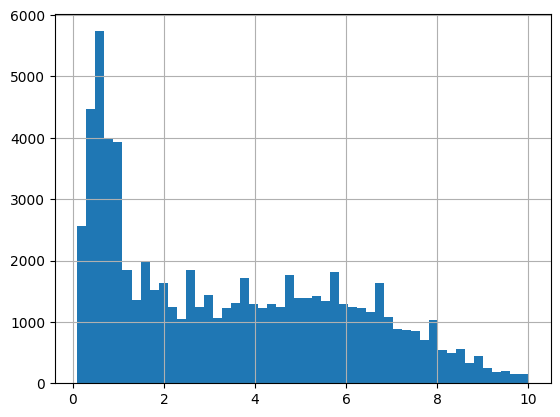

In [19]:
# Distribution of scores across all surfers in our frozen data
analysis.score.describe()
analysis.score.hist(bins=50)

## Pre-registration (written 11/1/26, before any model is run)
Question: Do surfers score higher at home breaks than their own away scores predict? \
Data: MCT, ocean breaks, 2014–2025 development set. 2026 is held out and untouched.\ 
Exclusions (frozen): sentinel heats, heats with data_quality_notes, interference zeros, zero scores.\
H1: the pooled home bump is above zero.\
H2: Brazil's home bump is larger than other nations' home bumps.\
Primary model: score ~ home + form + surfer effects + event effects; standard errors clustered by surfer.\
  form = average of the surfer's score relative to the event field over his previous K = 3 non-home events. \
Sensitivity: (A) surfer-by-year effects instead of form; (B) add surfer-by-break-handedness effects;
  (C) K = 2 and K = 5. \
Nation-level estimates only for nations with enough usable surfers; small nations pooled as "other".\
Caveat: a home bump could reflect favoritism or familiarity; this design cannot separate the two.

## Optional: save the frozen development table

In [ ]:
dev.to_csv("wsl_dev_waves_2014_2025.csv", index=False)
# dev.to_parquet("wsl_dev_waves_2014_2025.parquet")   # needs pyarrow; smaller and keeps dtypes